In [ ]:
%pip install matplotlib opencv-python scikit-learn

In [ ]:
%pip install setuptools

In [1]:
import os
import sys
import pickle
import numpy as np
import cv2
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from mtcnn import MTCNN
from tensorflow.keras.preprocessing import image
import tensorflow as tf

# 1. Apply the required module injection for VGGFace
sys.modules['keras.utils.layer_utils'] = tf.keras.utils
sys.modules['keras.utils.data_utils'] = tf.keras.utils
sys.modules['keras.backend'] = tf.keras.backend
sys.modules['keras.engine.topology'] = tf.keras.layers

from keras_vggface.utils import preprocess_input
from keras_vggface.vggface import VGGFace

# 2. Define Paths
PROJECT_ROOT = Path(r"E:\Python Projects\Celebrity_Face_matcher")
FEATURE_DIR = PROJECT_ROOT / "data" / "features"
# Create a folder for testing your random downloaded images
TEST_DIR = PROJECT_ROOT / "sample"
TEST_DIR.mkdir(parents=True, exist_ok=True)

# 3. Load Embeddings, Filenames, and Models
print("Loading embeddings and filenames...")
feature_list = np.array(pickle.load(open(FEATURE_DIR / 'embedding.pkl', 'rb')))
filenames = pickle.load(open(FEATURE_DIR / 'filenames.pkl', 'rb'))

print("Loading MTCNN Detector and VGGFace ResNet50...")
detector = MTCNN()
model = VGGFace(model='resnet50', include_top=False, input_shape=(224, 224, 3), pooling='avg')

# 4. Inference Function
def recognize_celebrity(test_image_path):
    # Load image for MTCNN
    sample_img = cv2.imread(str(test_image_path))
    if sample_img is None:
        raise ValueError(f"Could not read image at {test_image_path}")
        
    sample_img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
    
    # Detect Face
    results = detector.detect_faces(sample_img_rgb)
    if len(results) == 0:
        print("No face detected in the image.")
        return
    
    # Crop Face
    x, y, width, height = results[0]['box']
    face = sample_img_rgb[y:y+height, x:x+width]
    
    # Preprocess Face for VGGFace
    face_image = Image.fromarray(face)
    face_image = face_image.resize((224, 224))
    face_array = np.asarray(face_image).astype('float32')
    expanded_img = np.expand_dims(face_array, axis=0)
    preprocessed_img = preprocess_input(expanded_img)
    
    # Extract Features
    result = model.predict(preprocessed_img, verbose=0).flatten()
    
    # Calculate Cosine Similarity against all 15,842 identities
    similarity = []
    for i in range(len(feature_list)):
        similarity.append(cosine_similarity(result.reshape(1, -1), feature_list[i].reshape(1, -1))[0][0])
        
    index_pos = sorted(list(enumerate(similarity)), reverse=True, key=lambda x: x[1])[0][0]
    matched_image_path = filenames[index_pos]
    
    # Extract Celebrity Name from the path (e.g., data/processed/aamir_khan/aamir_khan_001.jpg -> Aamir Khan)
    matched_celeb_slug = Path(matched_image_path).parent.name
    matched_celeb_name = matched_celeb_slug.replace("_", " ").title()
    
    # 5. Display Results inline using Matplotlib
    matched_img = cv2.cvtColor(cv2.imread(matched_image_path), cv2.COLOR_BGR2RGB)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(sample_img_rgb)
    axes[0].set_title("Your Query Image")
    axes[0].axis('off')
    
    axes[1].imshow(matched_img)
    axes[1].set_title(f"Match: {matched_celeb_name}")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

print("\nReady for inference! Call recognize_celebrity('path_to_test_image.jpg')")


Loading embeddings and filenames...
Loading MTCNN Detector and VGGFace ResNet50...



Ready for inference! Call recognize_celebrity('path_to_test_image.jpg')


1/1 [==============================] - 0s 134ms/step


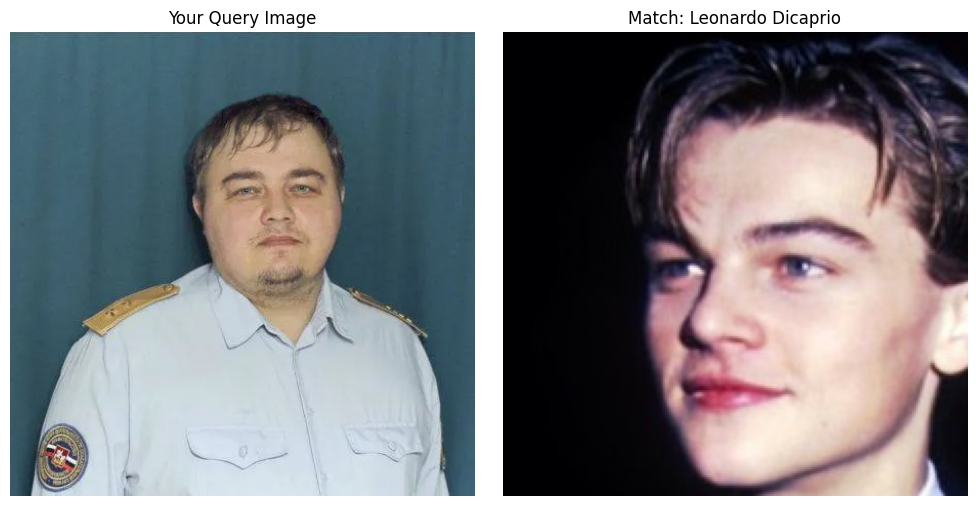

In [5]:
recognize_celebrity(r"E:\Python Projects\Celebrity_Face_matcher\sample\test_leo.jpg")